# 02 · Policy parametrizable: componentes, ablaciones y variante Hungarian

`candidate_strategy.py` (stdlib puro) es el archivo evaluado; aquí se importa su clase real y se **explica y mide** cada componente.
Encuadre: el despacho es un **MDP online** (estado = envíos pendientes + flota + hora; acción = qué grupo sale ahora y con qué carrier;
coste = dinero + penalización por tiempo y riesgo). La dinámica es un simulador cuyas probabilidades vienen dadas, así que se resuelve por
**aproximación de política** (regla paramétrica afinada por simulación), no por programación dinámica exacta (intratable y no cabe en el archivo evaluado).

| # | Componente | Qué decide | Fundamento |
|---|---|---|---|
| 1 | Grupos (cluster, zona, intento, capacidades) | qué tarjetas pueden ir en un lote | regla del motor |
| 2 | Retención ≤ tick de auditoría para clusters multi | cuándo salir para agrupar | linehaul por lote; 0 infracciones por construcción |
| 3 | Prioridad EDD | quién elige primero si hay contención | EDD minimiza la tardanza máxima (Jackson/Pinedo) |
| 4 | Carrier por valor esperado `J` | con quién | decisión bajo riesgo con probabilidades dadas |
| 5 | Modelo local de flota | despachar al llegar sin `snapshot()` | CPU |
| 6 | Mejoras mensuales por disparador | cuándo comprar una unidad | solo ante cola persistente |
| 7 | Asignación greedy vs Hungarian | cómo resolver la contención por tick | variante evaluada |

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()                 # solucion/
REPO = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import plotstyle as PS, figs
PS.apply()
CSV, FIG = ROOT / "outputs" / "csvs", ROOT / "outputs" / "figs"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
def show(fig):
    display(fig); plt.close(fig)

## 1 · Carrier por valor esperado: qué elige y cómo cambia con el valor del tiempo
`J = precio exacto + w_time · ETA + w_fail · P(fallo atribuible al carrier) · F(intento, zona) + coste sombra`. Se usa la **clase real** `CandidateStrategy._score`
con el catálogo del 5 k (día laborable, 14:00, primer intento, tarjeta no VIP). La probabilidad de ruta inaccesible solo depende de `HARD_ACCESS`; la de ausencia
no depende del carrier y por tanto no distingue.

In [2]:
import importlib, datetime as dt
sys.path.insert(0, str(REPO))                       # para 'interfaces'
import interfaces as I
sys.path.insert(0, str(REPO)); pol = importlib.import_module("candidate_strategy")
LIMA = dt.timezone(dt.timedelta(hours=-5)); T0 = dt.datetime(2026, 1, 7, 14, 0, tzinfo=LIMA)
car = json.load(open(REPO/"data"/"carriers.json"))["carriers"]
def snap(c):
    return I.CarrierSnapshot(c["carrier_id"], tuple(c["allowed_zones"]), tuple(c["capabilities"]), tuple(c["supported_upgrades"]), 3, 3, 3, 0,
        c["batch_capacity"], c["batch_capacity"], c["pickup_minutes"], c["speed_kmh"], 10000, c["base_fee_cents"],
        tuple(I.ZonePrice(z, c["zone_surcharge_cents"][z]) for z in c["allowed_zones"]), c["night_multiplier_bps"], c["holiday_multiplier_bps"],
        10000, True, T0, c["operational_failure_bps"], None, ())
class Svc:
    def snapshot(self): return tuple(snap(c) for c in car)
    def dispatch_batch(self, *a): raise RuntimeError
def best_carrier(zone, w_time, attempt=1, vip=False):
    st = pol.CandidateStrategy(Svc()); st.p.update(w_time=w_time)
    st._now_dt = T0; st._note_snapshot(Svc().snapshot(), T0); cars = st._cars_at(int(T0.timestamp())); st._build_ftab(cars)
    g = pol._Grp(("c", zone, attempt, (), 0), zone, attempt, (), 0); rec = pol._Rec("s", 0, vip, False); g.members.append(rec)
    caps = ("HARD_ACCESS",) if attempt > 1 and zone in ("RURAL","REMOTA") else ()
    sc = {c.cid: st._score(g, [rec], c) for c in cars if zone in c.zones and (not caps or "HARD_ACCESS" in c.caps)}
    return min(sc, key=sc.get)
wts = [0.25, 0.5, 1, 2, 3, 5, 8, 12, 20, 40]
zones = ["URBANA","SUBURBANA","RURAL","REMOTA"]
tabc = pd.DataFrame({w: {z: best_carrier(z, w) for z in zones} for w in wts}); tabc.columns = [f"w={w:g}" for w in wts]; tabc

,w=0.25,w=0.5,w=1,w=2,w=3,w=5,w=8,w=12,w=20,w=40
URBANA,ECO_POST,ECO_POST,ECO_POST,ECO_POST,COURIER_EXPRESS,COURIER_EXPRESS,COURIER_EXPRESS,COURIER_EXPRESS,COURIER_EXPRESS,VIP_FAST
SUBURBANA,ECO_POST,ECO_POST,SUBURBAN_MOTO,SUBURBAN_MOTO,COURIER_EXPRESS,COURIER_EXPRESS,COURIER_EXPRESS,COURIER_EXPRESS,VIP_FAST,VIP_FAST
RURAL,COURIER_EXPRESS,COURIER_EXPRESS,COURIER_EXPRESS,COURIER_EXPRESS,LOGI_GLOBAL,LOGI_GLOBAL,LOGI_GLOBAL,VIP_FAST,VIP_FAST,VIP_FAST
REMOTA,LOGI_GLOBAL,LOGI_GLOBAL,LOGI_GLOBAL,LOGI_GLOBAL,LOGI_GLOBAL,LOGI_GLOBAL,VIP_FAST,VIP_FAST,VIP_FAST,VIP_FAST


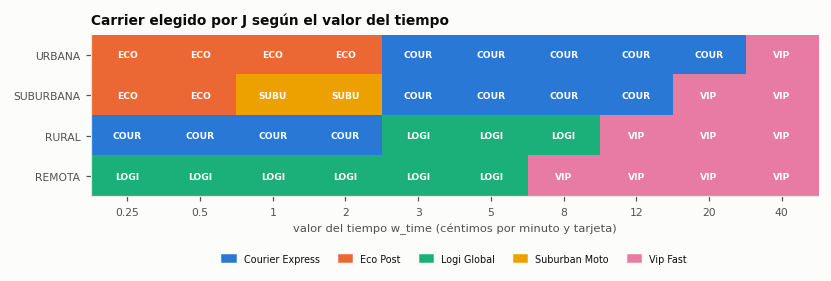

In [3]:
show(figs.carrier_choice(tabc))

Con `w_time` bajo manda el precio (ECO_POST/SUBURBAN_MOTO); al subir, la velocidad y la fiabilidad (COURIER_EXPRESS, luego VIP_FAST en zonas lejanas).
En RURAL/REMOTA el término de ruta inaccesible (4 %/12 % sin `HARD_ACCESS`) empuja a LOGI_GLOBAL aunque cueste más.

## 2 · Retención y gate: el tick de auditoría
El motor audita una tarjeta READY en el **primer tick ≥ ready+45 min** y el tick (prioridad 4) corre antes que la auditoría (prioridad 5).
La política libera el grupo exactamente en ese tick: nunca retiene de más. Comprobación medida: infracciones en todos los escenarios evaluados.

In [4]:
rb = pd.read_csv(CSV/"robustness_results_all.csv")
pc = rb[rb.candidate=="wt6_la240_up"]
print("candidatos de la política:", pc.candidate.nunique(), "| escenarios:", pc.scenario.nunique(), "| corridas:", len(pc))
print("infracciones de retención (suma, todas las corridas):", int(pc.hold_breaches.sum()))
print("infracciones del starter:", int(rb[rb.candidate=="starter"].hold_breaches.sum()), "| de ref_price:", int(rb[rb.candidate=="ref_price"].hold_breaches.sum()))
st_ = pol.CandidateStrategy(Svc()); st_._anchor = 0
print("tick de auditoría para ready=0 s, 1 s, 899 s, 900 s:", [st_._audit_ts(x) for x in (0, 1, 899, 900)])

candidatos de la política: 1 | escenarios: 75 | corridas: 75
infracciones de retención (suma, todas las corridas): 0
infracciones del starter: 3588 | de ref_price: 7
tick de auditoría para ready=0 s, 1 s, 899 s, 900 s: [2700, 3600, 3600, 3600]


## 3 · Aprendizaje en línea de clusters multi-tarjeta (sin hardcodear el significado del id)
El id de cluster del generador cambia de forma entre singleton (`CLU-S-…`) y multi (`CLU-E…`). La política **no** usa ese texto como regla:
guarda, por *forma* del id (dígitos → ∅), cuántos clusters cerrados resultaron multi, y retiene solo si `P(multi | forma) ≥ 0,5`.
Si los ids no informan (p. ej. ids opacos), `P` converge a la tasa base (≈ 0,15) y **no se retiene**.

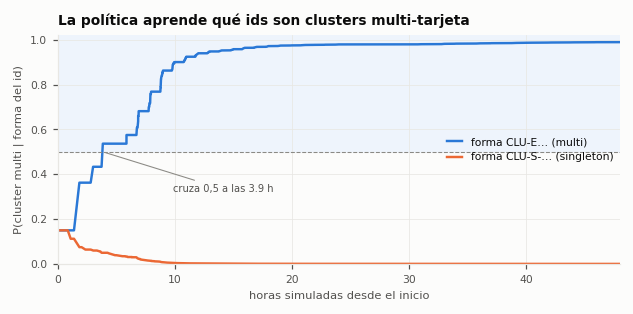

P(multi|CLU-E) cruza 0,5 tras 3.9 horas


In [5]:
d = pd.read_csv(REPO/"scenarios"/"public_150k"/"shipments.csv", nrows=40000); d["ts"] = pd.to_datetime(d.available_at.str.slice(0,19)).astype("int64")//10**9
st2 = pol.CandidateStrategy(Svc()); st2._anchor = 0
trace = []
for ts, cid in zip(d.ts, d.delivery_cluster_id):
    st2._expire_clusters(int(ts)); st2._note_cluster(cid, int(ts))
    trace.append((int(ts), st2._p_multi("CLU-E"), st2._p_multi("CLU-S-")))
tt = pd.DataFrame(trace, columns=["ts","P_E","P_S"]); tt["h"] = (tt.ts - tt.ts.iloc[0])/3600
show(figs.cluster_learning(tt))
first = tt[tt.P_E >= 0.5].h.iloc[0]; print("P(multi|CLU-E) cruza 0,5 tras", round(first, 1), "horas")

## Ablaciones (mismos escenarios TUNE, parámetros ganadores) y coste de CPU
`J` = objetivo del tuning (menor = mejor, referencia = más barata inmediata). `cpu_neta_5k_s` = mediana de 3 ejecuciones en serie sobre el 5 k público
menos el piso de la estrategia nula (misma sesión). Producido por `src/ablation.py`.

In [6]:
ab = pd.read_csv(CSV/"ablation_components.csv"); ab.round(3)

,variante,J,coste_vs_ref,lead_vs_ref,p95_vs_ref,rcp,lote_medio,gates_malos,cpu_neta_5k_s,rss_5k_mb
0,full,3.634,1.052,0.867,0.953,9.917,1.281,0,2.125,27.387
1,sin_retencion (hold_on=0),3.889,1.198,0.914,0.960,9.912,1.041,0,2.172,27.371
2,sin_despacho_al_llegar (solo ticks),3.621,1.055,0.893,0.957,9.921,1.282,0,2.188,27.316
3,hungarian_por_tick (assign=1),3.682,1.053,0.869,0.953,9.914,1.281,0,0.375,27.340
4,sin_riesgo_de_fallo (w_fail=0),3.684,0.967,0.931,0.966,9.914,1.279,0,-1.469,27.395
5,sin_valor_del_tiempo (w_time=0),3.868,0.867,1.040,1.004,9.896,1.279,0,-1.516,27.293
6,"sin_prioridad_VIP (w_vip=1, vip_fail_extra=0)",3.721,1.043,0.868,0.953,9.908,1.281,0,-1.500,27.355
7,sin_coste_sombra_flota (w_unit=0),3.634,1.052,0.867,0.953,9.917,1.281,0,-1.422,27.449
8,sin_liberar_cluster_completo,3.663,1.052,0.877,0.955,9.915,1.281,0,-1.422,27.285
9,sin_retener_segundo_miembro,3.634,1.053,0.866,0.953,9.917,1.280,0,-1.531,27.262


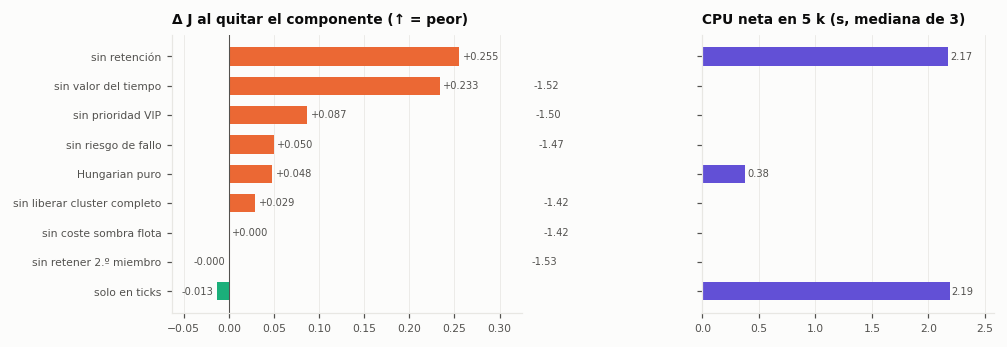

In [7]:
show(figs.ablation(ab))

### Variante: asignación óptima por tick (Hungarian / flujo de coste mínimo) vs greedy por prioridad
Medido sobre los mismos escenarios (fila `hungarian_por_tick (assign=1)` de la tabla): **no mejora** y empeora J (el emparejamiento que minimiza ΣJ deja sin unidad a los grupos
caros (VIP y urgentes) y cuesta más CPU). Por eso la versión final **no** usa Hungarian puro.

## Idea nueva (referencias consultadas + literatura): emparejamiento con **arrepentimiento** solo bajo escasez
Coste de emparejar el grupo g con una unidad del carrier c: `J(g,c) − M(g) − K`, con `M(g) = w_time·peso(g)·τ` (valor de los minutos de espera que se evitan) y `K` enorme:
(1) se emparejan tantos grupos como unidades factibles haya (si sobrara una unidad libre y factible, esperar sería una infracción de retención) y
(2) entre los emparejamientos máximos, las unidades escasas van a los grupos con mayor `M` (urgentes / VIP). Si hay unidades de sobra, se usa el greedy (cero coste extra).
Base: asignación (Eiselt & Sandblom §2.9), matching (Chen, Batson y Dang §5.3), y batching + Hungarian por ventana en despacho online (Lyft, arXiv 2503.13200).

In [8]:
la1 = pd.read_csv(CSV/"lookahead_assignment.csv"); la2 = pd.read_csv(CSV/"lookahead_assignment_tau2.csv")
la = pd.concat([la1, la2[la2.variante!="greedy"]]).drop_duplicates("variante")
cols = [c for c in la.columns if c.startswith("lead_")]
la[["variante"]+cols].round(0)

,variante,lead_tune_peak_0,lead_tune_peak_1,lead_tune_peak_2,lead_edge_stress_up,lead_edge_stress_xl,lead_edge_stress_noup,lead_edge_burst_1500,lead_tune_base_0,lead_tune_catalog_0,lead_tune_rural_holiday_0
0,greedy,256,228,233,1268,407,1268,9003,204,263,253
1,lookahead_tau15,256,224,234,975,782,975,7816,204,263,254
2,lookahead_tau60,256,220,234,948,777,948,7881,204,263,254
3,lookahead_tau240,256,218,233,761,505,761,7759,204,260,253
2,lookahead_tau600,255,217,233,737,459,737,7767,204,261,255
3,lookahead_tau1500,255,217,233,769,449,769,7767,204,261,255


Con la flota al 30 % del nominal, el emparejamiento baja el lead medio de 1 268 a 761 min sin mejoras mensuales y de 520 a 371 min con ellas. Con 12 000 tarjetas y flota al 45 % lo sube 2.0 % (no medí la causa). En escenarios normales y picos moderados el resultado es prácticamente idéntico. La mejora no depende finamente de τ (de 240 a 1 500 los resultados son cercanos): se fija **τ = 240**.

In [9]:
emp = pd.read_csv(CSV/"emparejamiento_casos_extremos.csv", index_col=0)
emp[["lead_con", "lead_greedy", "coste_con", "coste_greedy", "lead_%", "coste_%"]]

,lead_con,lead_greedy,coste_con,coste_greedy,lead_%,coste_%
scenario,,,,,,
edge_stress_up,371.1,519.6,3677594,3852642,-28.6,-4.54
edge_stress_noup,761.3,1268.0,4040005,4109432,-40.0,-1.69
edge_stress_xl,307.6,301.5,6685480,6492813,2.0,2.97
edge_opaque_ids,218.9,218.7,2194159,2186839,0.1,0.33
edge_no_upgrades,201.4,201.4,2001517,2001337,-0.0,0.01
edge_cap1,256.2,257.5,2091909,2089601,-0.5,0.11
edge_no_hard_access,258.3,257.5,2410887,2413957,0.3,-0.13
edge_all_closed_sun_hol,360.0,360.2,1930411,1922106,-0.1,0.43
edge_single_carrier,391.1,409.7,1017205,1015925,-4.5,0.13


**Error propio detectado por el conjunto EDGE:** la primera versión tenía un camino rápido para "un solo grupo" que cortaba el bucle con tarjetas pendientes; con carriers de capacidad 1
(`edge_cap1`) produjo **83 infracciones de retención**. Se corrigió y se reevaluó (0 infracciones en todos los escenarios factibles). Evidencia: `outputs/csvs/robustness_results_lookahead_v1_bug_cap1.csv`.